# Extension - label-free mixed-data clustering and stability (Part B)

**Question.** Without labels, do the bookings fall into real groups, and do those groups match cancellations?

**Brief and report.** Part B. Report Section 2, Table 3 and Figure 2. Training rows only; labels are used only after clustering, to score agreement.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

`mixed_clustering()` in `src/clustering.py` runs K-means twice: on numeric fields only, and on numeric plus one-hot category fields (each block weighted so neither dominates). Then:
1. k is chosen by the silhouette score, without labels.
2. Refitting on 20 subsamples measures stability: the ARI between each refit and the original clustering.
3. Only then are the clusters compared with cancellations (ARI and NMI).

**How to read the output.** High stability with near-zero agreement means stable segments of bookings that are not about cancellation. That is why the report recommends supervised learning.

Clustering | k selected: numeric: k = 4 (silhouette, no labels)


Clustering | k selected: mixed: k = 2 (silhouette, no labels)


,geometry,k,inertia,silhouette
0,numeric,2,31432.434,0.180
1,numeric,3,27899.636,0.196
2,numeric,4,23901.479,0.210
3,numeric,5,20762.296,0.199
4,numeric,6,18200.699,0.203
5,mixed,2,2176.117,0.171
6,mixed,3,1950.865,0.122
7,mixed,4,1813.020,0.116
8,mixed,5,1710.598,0.112
9,mixed,6,1623.473,0.110


,geometry,metric,mean,sd,ci_low,ci_high,n
0,mixed,stability_ari,0.764,3.730e-01,0.589,0.938,20
1,mixed,label_ari,0.037,1.651e-02,0.029,0.045,20
2,mixed,label_nmi,0.009,3.747e-03,0.008,0.011,20
3,numeric,stability_ari,0.948,4.080e-02,0.929,0.967,20
4,numeric,label_ari,0.039,3.310e-03,0.037,0.040,20
5,numeric,label_nmi,0.014,9.948e-04,0.013,0.014,20


,option,reference,metric,mean,sd,ci_low,ci_high,n,p_value,p_holm
0,mixed,numeric,stability_ari,-0.184,0.380,-0.362,-0.006,20,7.475e-01,1.000e+00
1,mixed,numeric,label_ari,-0.002,0.018,-0.010,0.006,20,5.958e-01,1.000e+00
2,mixed,numeric,label_nmi,-0.005,0.004,-0.006,-0.003,20,1.907e-06,5.722e-06


,geometry,k,cluster,rows,cancellation_fraction,median_lead_time,median_adr,modal_hotel,modal_market_segment
0,numeric,4,0,1279,0.357,143.0,106.00,City Hotel,Online TA
1,numeric,4,1,328,0.375,51.0,158.93,City Hotel,Online TA
2,numeric,4,2,2351,0.218,21.0,89.25,City Hotel,Online TA
3,numeric,4,3,42,0.214,59.5,96.95,Resort Hotel,Online TA
4,mixed,2,0,2942,0.247,30.0,95.40,City Hotel,Online TA
5,mixed,2,1,1058,0.354,147.0,108.00,Resort Hotel,Online TA


**reports/figures/fig_B_02_mixed_k.png**

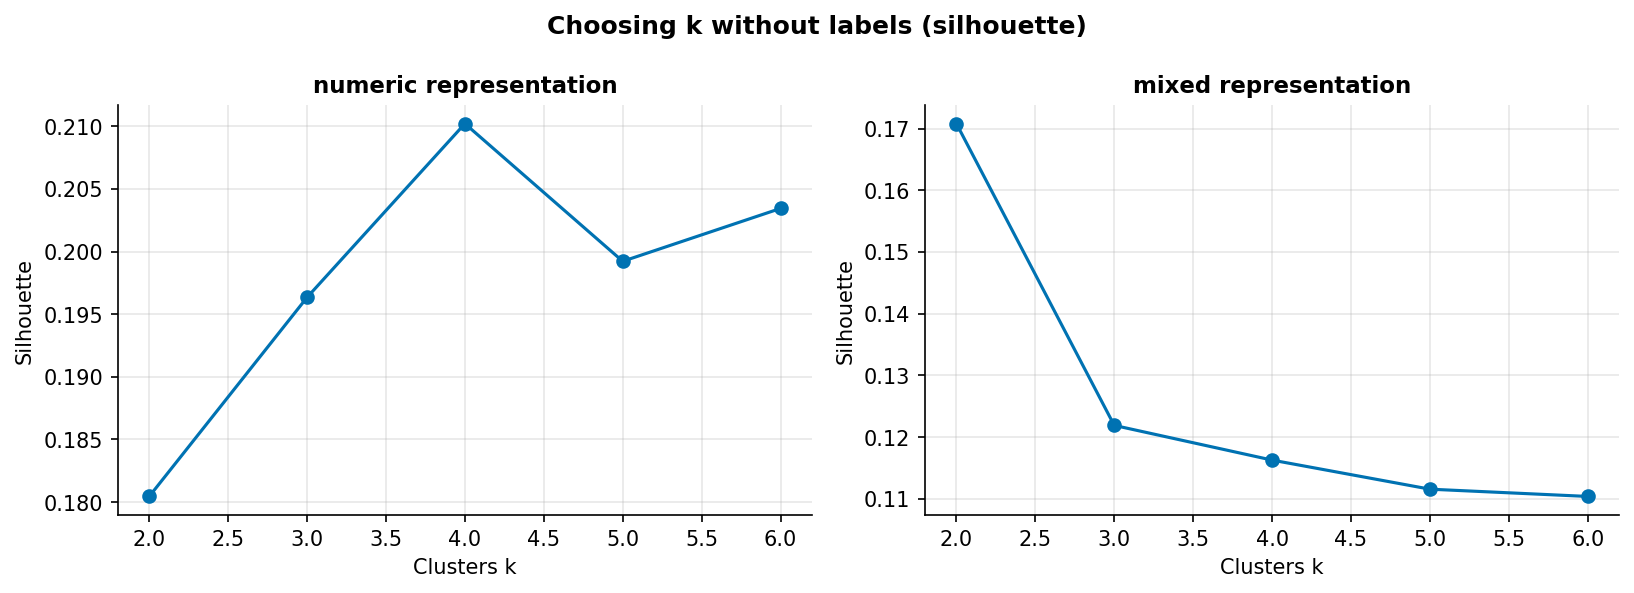

**reports/figures/fig_B_03_cluster_stability.png**

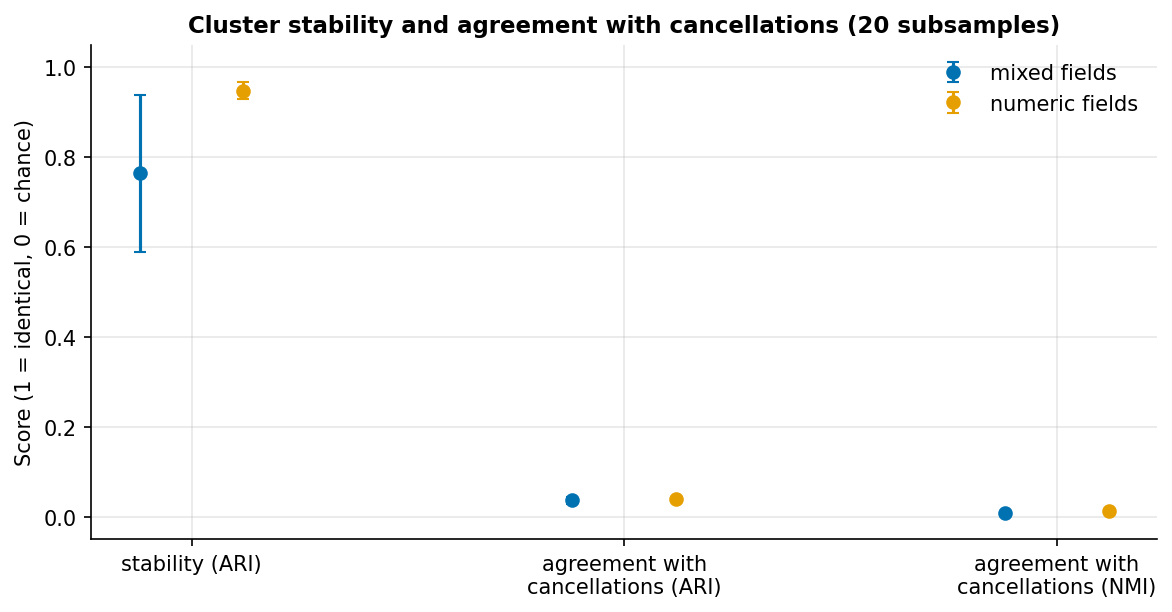

In [2]:
from src.clustering import mixed_clustering
trials, summary, comparison = mixed_clustering()
display(trials)
display(summary)
display(comparison)
display(results('d2_4_cluster_profiles.csv'))
show('fig_B_02_mixed_k.png', 'fig_B_03_cluster_stability.png')

### Methods built for mixed data (added 13 November 2026)
K-means treats one-hot category columns as distances, which can distort mixed data. `mixed_data_clustering()` in `src/clustering.py` runs two methods made for mixed fields on the same pool, anchors and subsamples as above: **k-prototypes** (squared distances on the numbers plus `GAMMA` times the number of category mismatches) and **k-medoids on Gower distance** (every field scaled to 0-1 and averaged). k is chosen without labels by silhouette on Gower distance. Labels are used only to score agreement afterwards.

**How to read the output.** The first table shows the silhouette for each k. The summary gives stability and agreement for all four methods over 20 subsamples, and the last table tests whether each new method agrees with cancellations more than K-means on mixed fields (Holm-adjusted).

Mixed-data clustering | k selected: Gower k-medoids: k = 4 (silhouette on Gower distance, no labels)


Mixed-data clustering | k selected: k-prototypes: k = 4 (silhouette on Gower distance, no labels)


,method,k,silhouette_gower,smallest_cluster
0,k-prototypes,2,0.071,1734
1,Gower k-medoids,2,0.287,1569
2,k-prototypes,3,0.091,334
3,Gower k-medoids,3,0.288,668
4,k-prototypes,4,0.092,330
5,Gower k-medoids,4,0.292,425
6,k-prototypes,5,0.058,305
7,Gower k-medoids,5,0.259,344
8,k-prototypes,6,0.053,297
9,Gower k-medoids,6,0.248,183


,geometry,metric,mean,sd,ci_low,ci_high,n
0,K-means numeric,stability_ari,0.948,4.080e-02,0.929,0.967,20
1,K-means numeric,label_ari,0.039,3.310e-03,0.037,0.040,20
2,K-means numeric,label_nmi,0.014,9.948e-04,0.013,0.014,20
3,K-means mixed,stability_ari,0.764,3.730e-01,0.589,0.938,20
4,K-means mixed,label_ari,0.037,1.651e-02,0.029,0.045,20
5,K-means mixed,label_nmi,0.009,3.747e-03,0.008,0.011,20
6,Gower k-medoids,stability_ari,0.408,1.282e-01,0.348,0.468,20
7,Gower k-medoids,label_ari,-0.013,9.287e-03,-0.018,-0.009,20
8,Gower k-medoids,label_nmi,0.024,6.053e-03,0.021,0.027,20
9,k-prototypes,stability_ari,0.977,1.318e-02,0.970,0.983,20


,option,reference,metric,mean,sd,ci_low,ci_high,n,p_value,p_holm
0,Gower k-medoids,K-means mixed,label_ari,-0.050,0.018,-0.059,-0.042,20,1.907e-06,3.815e-06
1,k-prototypes,K-means mixed,label_ari,-0.031,0.017,-0.038,-0.023,20,9.537e-06,9.537e-06


**reports/figures/fig_B_04_mixed_methods.png**

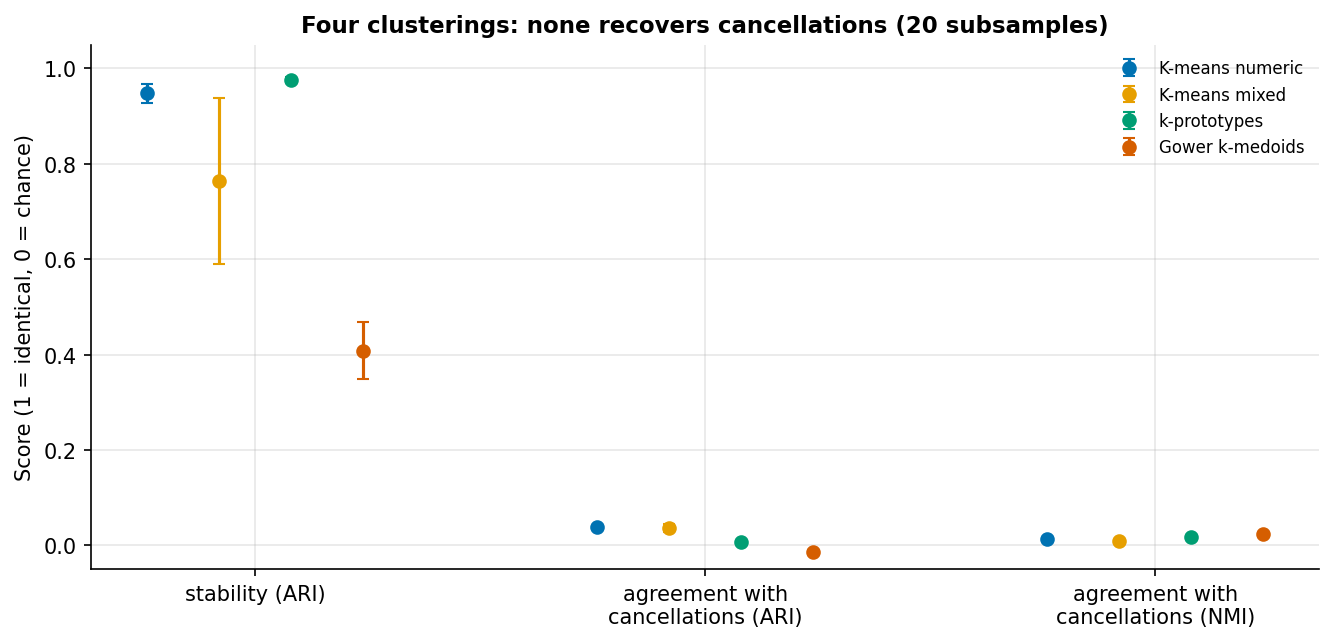

In [3]:
from src.clustering import mixed_data_clustering
mixed_trials, mixed_summary, mixed_comparison = mixed_data_clustering()
display(mixed_trials)
display(mixed_summary)
display(mixed_comparison)
show('fig_B_04_mixed_methods.png')